# 🛠️ **IMPORTS**: Bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 💻 **CÓDIGOS**: Implementação

In [2]:
file_censo = '../data/censo2022/br_ibge_censo_2022_municipio.xlsx'
output_file_csv = '../data/censo2022/dados_demograficos_uf.csv'

df_censo = pd.read_excel(file_censo)
print("Arquivos carregados com sucesso.")

Arquivos carregados com sucesso.


In [3]:
#COLUNAS
df_demografia = df_censo[['sigla_uf', 'idade_mediana', 'indice_envelhecimento']].copy()

#CORRIGIR ERROS
df_demografia['idade_mediana'] = pd.to_numeric(df_demografia['idade_mediana'], errors='coerce')
df_demografia['indice_envelhecimento'] = pd.to_numeric(df_demografia['indice_envelhecimento'], errors='coerce')

df_demografia.dropna(subset=['idade_mediana', 'indice_envelhecimento'], inplace=True)

#MEDIA
df_agregado = df_demografia.groupby('sigla_uf').mean().reset_index()

#ORDENAR PELO UF
df_agregado_sorted = df_agregado.sort_values(by='sigla_uf')

print("\n--- Média de Idade Mediana e Índice de Envelhecimento por UF (Top 5) ---")
print(df_agregado_sorted.head())

df_agregado_sorted.to_csv(output_file_csv, index=False, encoding='utf-8')


--- Média de Idade Mediana e Índice de Envelhecimento por UF (Top 5) ---
  sigla_uf  idade_mediana  indice_envelhecimento
0       AC      25.136364              20.792727
1       AL      30.686275              38.777157
2       AM      23.580645              17.520645
3       AP      24.375000              16.819375
4       BA      34.479616              58.447098


# 📊 Gráfico de Linha (Duplo Eixo Y): Média da Idade Mediana e Índice de Envelhecimento por UF

---

### Descrição das Séries de Dados:

- **Idade Mediana (em azul):** 
  - Representa a idade que divide a população em duas metades iguais: 50% mais jovens e 50% mais velhos.
  - **Interpretação:** Estados com valores mais altos indicam uma população mais envelhecida.
  
- **Índice de Envelhecimento (em vermelho, eixo secundário):**
  - Indica o número de pessoas de 60 anos ou mais para cada 100 pessoas de 0 a 14 anos.
  - **Interpretação:** Valores mais altos refletem maior pressão social e econômica ligada ao envelhecimento populacional.

---

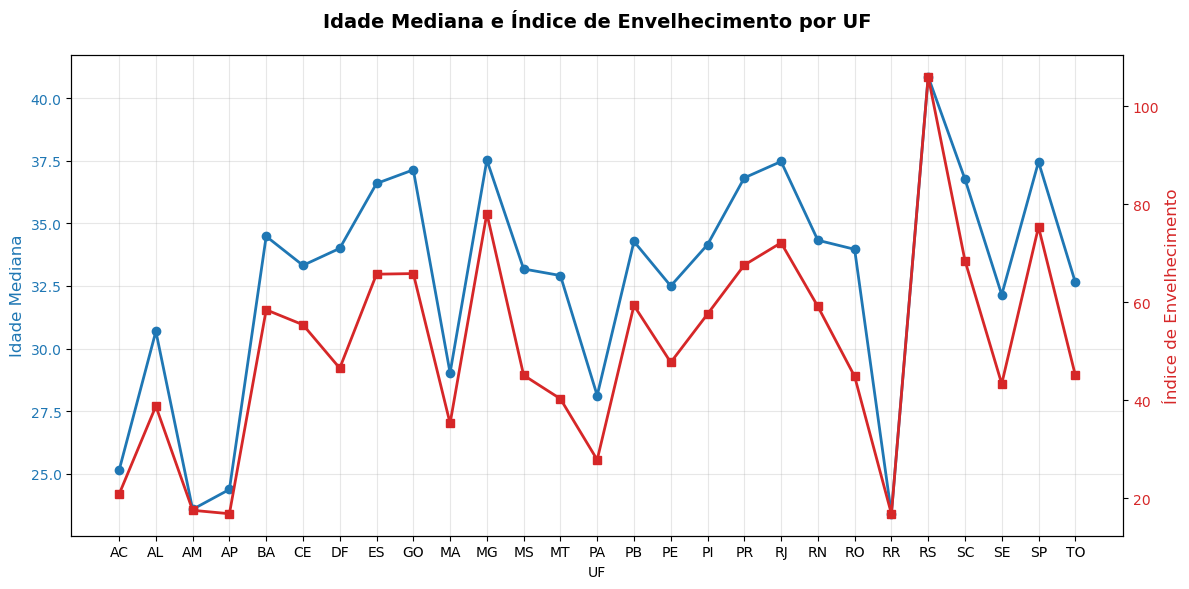

In [4]:
fig, ax1 = plt.subplots(figsize=(12, 6))

#Y1 MEDIANA
color = 'tab:blue'
ax1.set_xlabel('UF')
ax1.set_ylabel('Idade Mediana', color=color, fontsize=12)
line1 = ax1.plot(df_agregado_sorted['sigla_uf'], df_agregado_sorted['idade_mediana'], 
                 color=color, marker='o', linewidth=2, label='Idade Mediana')
ax1.tick_params(axis='y', labelcolor=color)

#Y2 ENVELHECIMENTO
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Índice de Envelhecimento', color=color, fontsize=12)
line2 = ax2.plot(df_agregado_sorted['sigla_uf'], df_agregado_sorted['indice_envelhecimento'], 
                 color=color, marker='s', linewidth=2, label='Índice de Envelhecimento')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Idade Mediana e Índice de Envelhecimento por UF', fontsize=14, fontweight='bold', pad=20)
ax1.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()